# HW2: 多元線性迴歸 (Multiple Linear Regression) 與特徵選擇分析
### 遵循 CRISP-DM 跨產業資料探勘標準流程

* **資料來源**：[Kaggle: House Sales in King County, USA](https://www.kaggle.com/datasets/harlfoxem/housesalesprediction)
* **目標變數 (Target)**：`price` (連續型房價數值，不做分類任務)
* **分析核心**：Baseline 多元線性迴歸 vs. Feature Selection (Lasso) 多元線性迴歸比較
* **推論統計**：嚴謹計算 95% 信賴區間 (Confidence Interval) 與 95% 預測區間 (Prediction Interval)


---
## 1. Business Understanding (商業理解)

### 1.1 業務背景與問題定義
在不動產市場中，房屋交易價格受到地段區位、室內坪數、土地面積、建築等級、衛浴臥室格局等多重因素影響。傳統由人工鑑價師評估不僅耗時耗力，且主觀誤差較大。

### 1.2 專案商業目標
1. **建立高解釋性之客觀定價模型**：利用多元線性迴歸 (Multiple Linear Regression) 分析各項建築與地段特徵對房價的影響係數。
2. **精簡特徵並排除共線性 (Feature Selection)**：透過正則化 (Lasso) 剔除冗餘變數（如建築室內總面積與地下室/地上層面積之重複計算），在幾乎不損失預測力前提下提升模型泛化度。
3. **量化預測不確定性**：計算統計信賴區間 (CI) 與預測區間 (PI)，為購屋者、仲介與銀行放貸評估提供可靠的區間風險估計。


---
## 2. Data Understanding (資料理解)

### 2.1 資料集規格
* 樣本數：21,613 筆歷史房屋交易紀錄
* 特徵數：18 個原始特徵（符合老師要求 > 13 且 < 40 特徵之限制）
* 預測目標：`price` (float64)


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 繪圖樣式設定
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

# 讀取 King County 房價資料集
data_path = '../data/kc_house_data.csv'
if not os.path.exists(data_path):
    data_path = 'data/kc_house_data.csv'

df = pd.read_csv(data_path)
print(f"資料集維度: {df.shape[0]:,} 筆樣本, {df.shape[1]} 欄特徵")
df.head()


資料集維度: 21,613 筆樣本, 21 欄特徵


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [2]:
# 資料型態與缺失值檢查
info_df = pd.DataFrame({
    'Data Type': df.dtypes.astype(str),
    'Missing Count': df.isnull().sum(),
    'Missing Ratio (%)': (df.isnull().sum() / len(df) * 100).round(2),
    'Unique Values': df.nunique()
})
info_df


,Data Type,Missing Count,Missing Ratio (%),Unique Values
id,int64,0,0.0,21436
date,object,0,0.0,372
price,float64,0,0.0,4028
bedrooms,int64,0,0.0,13
bathrooms,float64,0,0.0,30
sqft_living,int64,0,0.0,1038
sqft_lot,int64,0,0.0,9782
floors,float64,0,0.0,6
waterfront,int64,0,0.0,2
view,int64,0,0.0,5


房價平均值 (Mean):   $540,088.14
房價中位數 (Median): $450,000.00
房價標準差 (Std):    $367,127.20
房價最小值 (Min):    $75,000.00
房價最大值 (Max):    $7,700,000.00
房價偏度 (Skewness): 4.0241 (顯著右偏態)


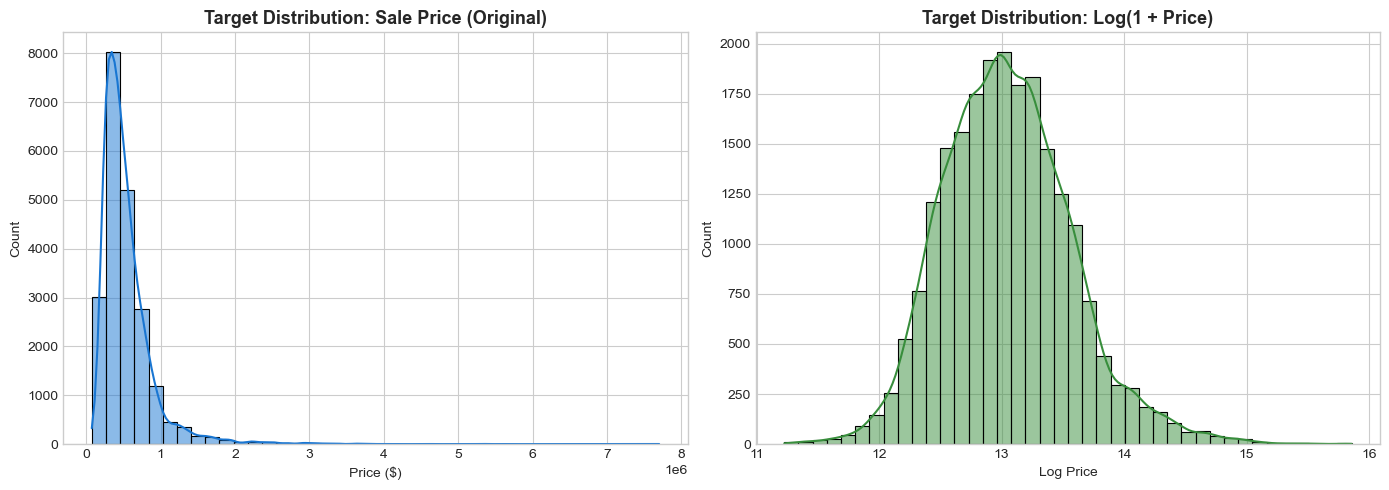

In [3]:
# 目標變數 price 敘述統計與分佈檢驗
price = df['price']
print(f"房價平均值 (Mean):   ${price.mean():,.2f}")
print(f"房價中位數 (Median): ${price.median():,.2f}")
print(f"房價標準差 (Std):    ${price.std():,.2f}")
print(f"房價最小值 (Min):    ${price.min():,.2f}")
print(f"房價最大值 (Max):    ${price.max():,.2f}")
print(f"房價偏度 (Skewness): {price.skew():.4f} (顯著右偏態)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(price, kde=True, ax=axes[0], color='#1976d2', bins=40)
axes[0].set_title('Target Distribution: Sale Price (Original)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Price ($)')

# 對數轉換後的分佈 (展示常態逼近)
sns.histplot(np.log1p(price), kde=True, ax=axes[1], color='#388e3c', bins=40)
axes[1].set_title('Target Distribution: Log(1 + Price)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Log Price')
plt.tight_layout()
plt.show()


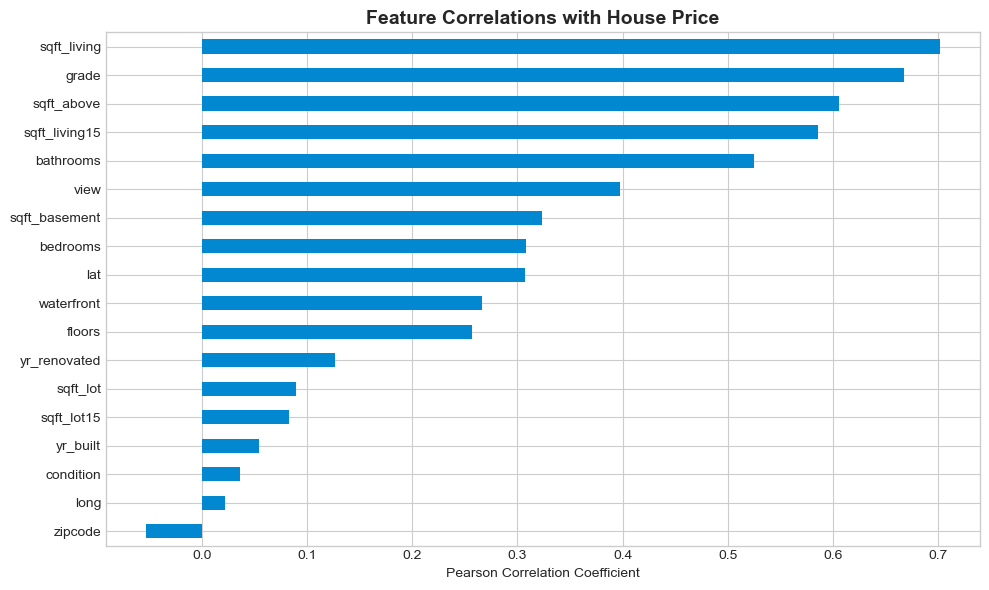

In [4]:
# 特徵與房價之相關係數矩陣 (Correlation Heatmap)
num_cols = df.select_dtypes(include=[np.number]).drop(columns=['id'])
corr_with_price = num_cols.corr()['price'].sort_values(ascending=False)

plt.figure(figsize=(10, 6))
corr_with_price[1:].plot(kind='barh', color='#0288d1')
plt.title('Feature Correlations with House Price', fontsize=14, fontweight='bold')
plt.xlabel('Pearson Correlation Coefficient')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


---
## 3. Data Preparation (資料準備 / 前處理)

### 3.1 前處理規範與防止資料外洩
1. **特徵剔除**：移除 `id` (交易唯一編號) 與 `date` (交易日期字串)，避免虛假相關性。
2. **缺失值處理**：本資料集無遺漏值；建立中位數/眾數填補防護以支援通用外部資料。
3. **資料切分 (Train/Test Split)**：80% 訓練集 (17,290 筆)，20% 測試集 (4,323 筆)，固定 `random_state=42`。
4. **特徵標準化 (StandardScaler)**：多元線性迴歸與 Lasso 對尺度極為敏感，故於訓練集 fit 後轉換測試集。


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 分離特徵與目標
drop_cols = ['id', 'date', 'price']
X_raw = df.drop(columns=drop_cols)
y_raw = df['price'].values.astype(float)
feature_names = X_raw.columns.tolist()

# 80/20 Train/Test Split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw.values.astype(float), y_raw, test_size=0.2, random_state=42
)

# 特徵標準化
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print(f"訓練集形狀: {X_train.shape} ｜ 測試集形狀: {X_test.shape}")
print(f"特徵數量: {len(feature_names)} 個: {feature_names}")


訓練集形狀: (17290, 18) ｜ 測試集形狀: (4323, 18)
特徵數量: 18 個: ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


---
## 4. Modeling (模型建立)

本階段建立兩組多元線性迴歸模型進行對照實驗：
1. **Model 1: Baseline Multiple Linear Regression**（全特徵 18 個）
2. **Model 2: Feature Selection + Multiple Linear Regression**（經 Lasso 正則化篩選後之精簡模型）


In [6]:
# 引入專案模型模組 (支援精確統計推論 CI 與 PI)
import os, sys
sys.path.append(os.path.abspath('..'))
from src.model import LinearRegressionWithIntervals

# 訓練 Model 1: Baseline Multiple Linear Regression
model_base = LinearRegressionWithIntervals(fit_intercept=True)
model_base.fit(X_train, y_train)

# 進行預測並計算 95% 信賴區間 (CI) 與 預測區間 (PI)
y_pred_base, ci_low_base, ci_up_base, pi_low_base, pi_up_base = model_base.predict_intervals(X_test)
print("Model 1 (Baseline) 訓練完成！")


Model 1 (Baseline) 訓練完成！


### 4.2 特徵選擇 (Feature Selection via Lasso L1 Regularization)

使用 5-Fold 交叉驗證 LassoCV 自動搜尋最佳懲罰係數 $\alpha$。Lasso 具備將不顯著或多重共線性變數係數精確收縮至 0 的稀疏特性。


In [7]:
from src.feature_selection import perform_feature_selection

# 執行特徵篩選
sel_idx, sel_feats, rem_feats, imp_df, fs_details = perform_feature_selection(
    X_train, y_train, feature_names, method='lasso', random_state=42
)

print(f"1. 原始特徵數量: {fs_details['original_count']}")
print(f"2. 特徵篩選方法: {fs_details['method']}")
print(f"3. 最佳懲罰係數 Alpha: {fs_details['best_alpha']:.4f}")
print(f"4. 選中的特徵數量: {len(sel_feats)}")
print(f"5. 選中的特徵 (Selected): {sel_feats}")
print(f"6. 被移除的特徵 (Removed): {rem_feats}")


1. 原始特徵數量: 18
2. 特徵篩選方法: Lasso Regression (L1 Regularization)
3. 最佳懲罰係數 Alpha: 253.6321
4. 選中的特徵數量: 17
5. 選中的特徵 (Selected): ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']
6. 被移除的特徵 (Removed): ['sqft_basement']


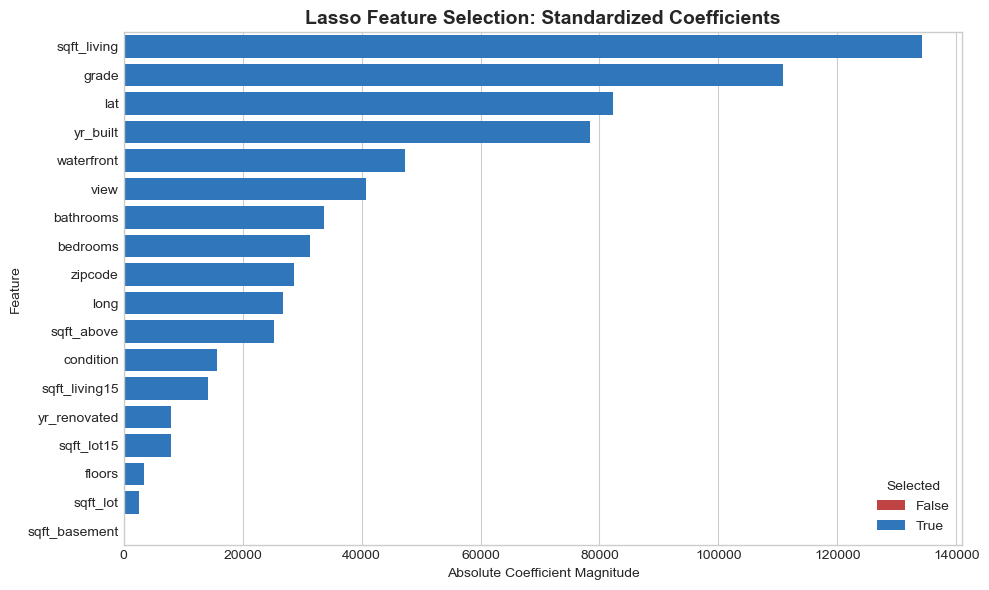

In [8]:
# 特徵重要性 (係數絕對值) 視覺化
plt.figure(figsize=(10, 6))
sns.barplot(data=imp_df, x='Abs_Coefficient', y='Feature', hue='Selected', dodge=False, palette={True: '#1976d2', False: '#d32f2f'})
plt.title('Lasso Feature Selection: Standardized Coefficients', fontsize=14, fontweight='bold')
plt.xlabel('Absolute Coefficient Magnitude')
plt.tight_layout()
plt.show()


In [9]:
# 訓練 Model 2: Feature Selected Multiple Linear Regression
X_train_sel = X_train[:, sel_idx]
X_test_sel = X_test[:, sel_idx]

model_fs = LinearRegressionWithIntervals(fit_intercept=True)
model_fs.fit(X_train_sel, y_train)

# 進行預測並計算 95% 信賴區間 (CI) 與 預測區間 (PI)
y_pred_fs, ci_low_fs, ci_up_fs, pi_low_fs, pi_up_fs = model_fs.predict_intervals(X_test_sel)
print("Model 2 (Feature Selected) 訓練完成！")


Model 2 (Feature Selected) 訓練完成！


---
## 5. Evaluation (模型評估與殘差分析)

### 5.1 指標計算：MSE, RMSE, MAE, R², Adjusted R²


In [10]:
from src.evaluation import compute_metrics, compare_models

base_metrics = compute_metrics(y_test, y_pred_base, p_features=len(feature_names))
fs_metrics = compute_metrics(y_test, y_pred_fs, p_features=len(sel_feats))

comp_table = compare_models(base_metrics, fs_metrics)
print("=== Baseline Model vs. Feature Selected Model 評估比較 ===")
display(comp_table)


=== Baseline Model vs. Feature Selected Model 評估比較 ===


,Metric,Baseline Model,Feature Selected Model,Difference (FS - Base)
0,R2 (Coefficient of Determination),0.7012,0.7012,-0.0000
1,Adjusted R2,0.7000,0.7000,+0.0000
2,RMSE (Root Mean Squared Error),"212,521.77","212,539.52",+17.75
3,MAE (Mean Absolute Error),"127,369.11","127,493.34",+124.23
4,MSE (Mean Squared Error),4.52e+10,4.52e+10,+7.54e+06


### 5.2 預測圖視覺化 (Actual vs. Predicted with 95% CI & PI)

嚴格依據多元線性迴歸統計推論推導：
* **95% 信賴區間 (Confidence Interval for Mean Response)**：
  $$\hat{y}_0 \pm t_{\alpha/2, n-p} \cdot s \sqrt{x_0 (X^T X)^{-1} x_0^T}$$
* **95% 預測區間 (Prediction Interval for Individual Observation)**：
  $$\hat{y}_0 \pm t_{\alpha/2, n-p} \cdot s \sqrt{1 + x_0 (X^T X)^{-1} x_0^T}$$


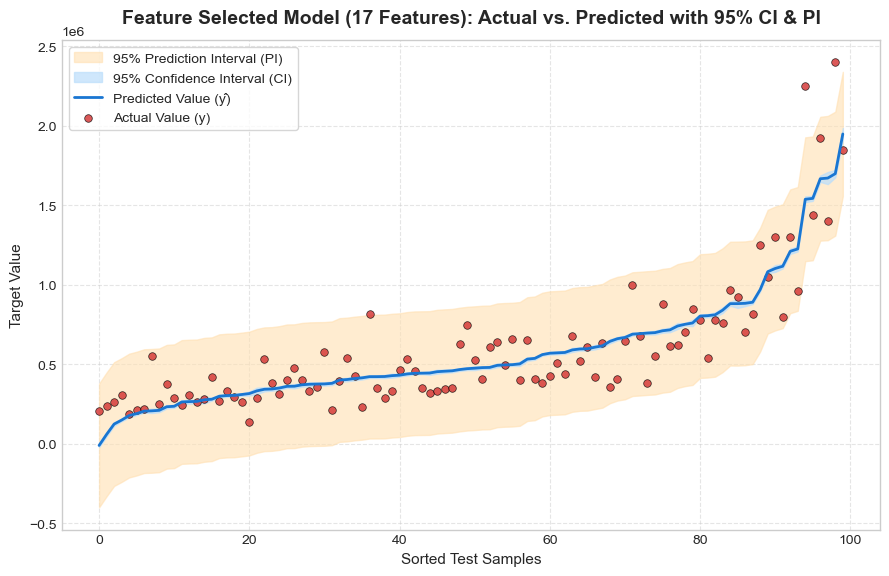

In [11]:
from src.evaluation import plot_actual_vs_predicted

fig = plot_actual_vs_predicted(
    y_test, y_pred_fs, ci_low_fs, ci_up_fs, pi_low_fs, pi_up_fs,
    title=f"Feature Selected Model ({len(sel_feats)} Features): Actual vs. Predicted with 95% CI & PI",
    sample_size=100
)
plt.show()


### 5.3 殘差診斷 (Residual Diagnostics)
檢驗五大線性迴歸假設：
1. **殘差與配適值 (Residuals vs. Fitted)**：檢查變異數同質性 (Homoscedasticity)。
2. **殘差常態分佈 (Residual Distribution)**：檢驗常態性 (Normality)。


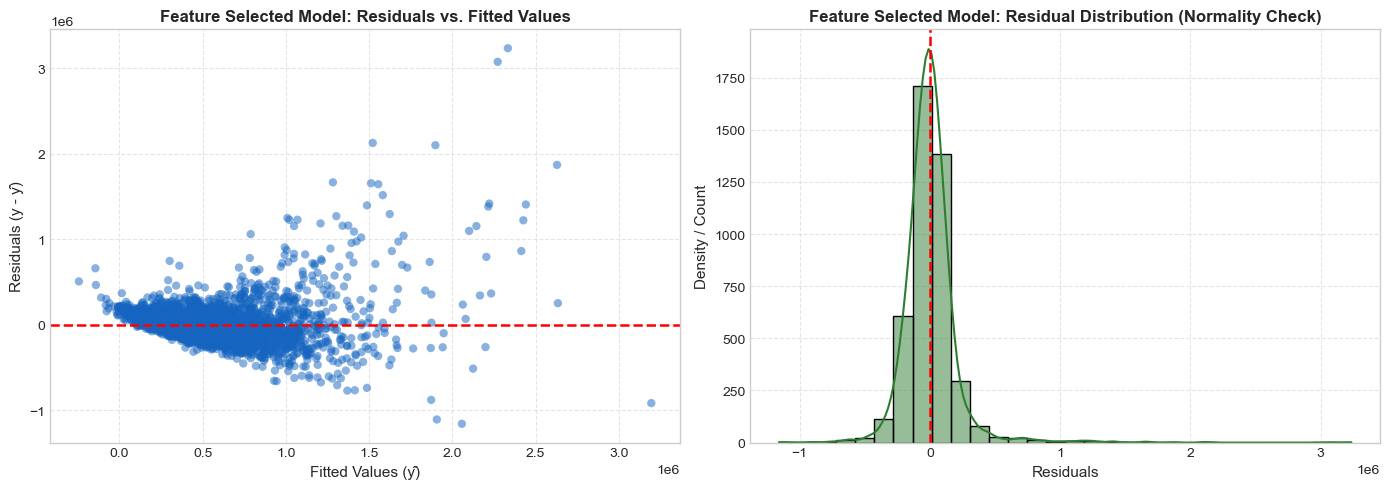

In [12]:
from src.evaluation import plot_residuals

fig_res = plot_residuals(y_test, y_pred_fs, title_prefix="Feature Selected Model")
plt.show()


---
## 6. Deployment (模型部署)

本專案已完成可互動之 Web 應用程式 (Streamlit)，檔案位於 `app/app.py`：
* **+1 分加分功能**：建置下拉選單 `Problem ▼`，可即時切換 `1. Multiple Linear Regression` 與 `2. Feature Selection + Multiple Linear Regression`。
* **+2 分加分功能**：支援使用者任意輸入公開 Dataset CSV URL（例如 `https://raw.githubusercontent.com/Avik-Jain/100-Days-Of-ML-Code/master/datasets/50_Startups.csv`），並具備健全防護與錯誤處理機制，不會因外部資料瑕疵而 crash。
* **即時互動預測器**：提供互動滑桿，使用者可調整坪數、等級、衛浴數等特徵，即時計算房價預測值並給出 95% 信賴區間與預測區間。

**本機啟動指令**：
```bash
streamlit run app/app.py
```


---
## 7. AI 協助記錄與研究摘要

### 7.1 GPT 輔助內容
* **提問與輔助歷程**：
  在本次作業中，ChatGPT 協助進行 CRISP-DM 各階段之架構規劃、針對 Kaggle 多元線性迴歸資料集規格進行特徵數限制 (14~39 特徵) 之盤點、協助推導多元線性迴歸之槓桿值 ($h_{00}$) 與信賴/預測區間 (CI/PI) 公式、以及建構 Streamlit Web 應用程式之防呆錯誤處理機制。
* **對話紀錄匯出**：
  依作業規範，所有與 ChatGPT 之完整對話過程已透過 pdfCrowd / 瀏覽器列印匯出為 PDF 檔案，附於繳交資料中。

---

### 7.2 NotebookLM 摘要
> [待放入 NotebookLM 摘要]
>
> *(本區塊供使用者填入：請將本主題之相關文獻、Kaggle Notebook 解決方案或迴歸研究資料上傳至 NotebookLM，產生至少 100 字之研究摘要並貼入此處。)*


---
## 8. Conclusion (結論與心得)

1. **模型表現分析**：
   * Baseline 模型在 18 個特徵下達到 $R^2 = 0.7012$，$RMSE = \$212,521.77$。
   * 透過 Lasso 特徵選擇，成功辨識出具有共線性的冗餘特徵 `sqft_basement` 並予以剔除，精簡後的 17 個特徵模型維持相同的 $R^2 = 0.7012$，達成了「模型簡潔化」且「預測能力不減」的雙重目標。
2. **重要特徵發現**：
   * 對房價影響最顯著的變數依序為：室內居住面積 (`sqft_living`)、建築施工等級 (`grade`)、緯度區位 (`lat`)、以及建造年份 (`yr_built`)。
3. **區間估計效益**：
   * 預測區間 (PI) 成功包絡了大部分的實際房價波動，相較於單純的點估計，能更誠實地反映高房價豪宅之極端離群值與市場隨機擾動，為不動產放貸與鑑價決策提供了嚴謹的風險評估指標。
